<a href="https://colab.research.google.com/github/sivakrishna536/sample-program/blob/main/Nail_disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install timm albumentations opencv-python-headless


In [ ]:
import os
import shutil
from google.colab import files

# 1. Create clean folder structures automatically
for folder_name in ['healthy', 'fungus', 'psoriasis']:
    os.makedirs(f'/content/Nail_Dataset/{folder_name}', exist_ok=True)

print("✨ Step A complete: The classification folders are built inside the AI environment.")
print("👉 Click the 'Choose Files' button that appears below to pick your photos.")
print("⚠️ CRITICAL: Upload only one category at a time! Start with your HEALTHY photos first.")

# 2. Trigger the automated pop-up selector window
uploaded = files.upload()

# 3. Move the files to the correct target folder
for filename in uploaded.keys():
    # Detect the filename extensions safely
    if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.webp', '.avif')):
        src_path = filename
        # Send them into the healthy directory
        dst_path = os.path.join('/content/Nail_Dataset/healthy', filename)
        shutil.move(src_path, dst_path)

print("\n✅ SUCCESS: Your healthy photos are safely imported into the training pipeline!")

✨ Step A complete: The classification folders are built inside the AI environment.
👉 Click the 'Choose Files' button that appears below to pick your photos.
⚠️ CRITICAL: Upload only one category at a time! Start with your HEALTHY photos first.


Saving klrs4.jpg to klrs4.jpg
Saving klrs5.jpg to klrs5.jpg
Saving klrs6.jpg to klrs6.jpg
Saving klrs7.jpg to klrs7.jpg
Saving klrs8.jpg to klrs8.jpg
Saving klrs8.webp to klrs8.webp
Saving klrs9.webp to klrs9.webp
Saving klrs11.jpg to klrs11.jpg
Saving klrs12.jpg to klrs12.jpg
Saving klrs13.jpg to klrs13.jpg
Saving klrs14.webp to klrs14.webp
Saving klrs15.jpg to klrs15.jpg
Saving klrs16.jpeg to klrs16.jpeg
Saving klrs17.jpg to klrs17.jpg
Saving klrs18.jpg to klrs18.jpg
Saving klrs19.jpg to klrs19.jpg
Saving klrs20.webp to klrs20.webp
Saving klrs21.jpg to klrs21.jpg
Saving klrs22.jpg to klrs22.jpg
Saving klrs23.jpg to klrs23.jpg

✅ SUCCESS: Your healthy photos are safely imported into the training pipeline!


In [ ]:
from google.colab import files
import os
import shutil

print("👉 Click 'Choose Files' below and select ONLY your PSORIASIS photos from your desktop.")
uploaded_psoriasis = files.upload()

for filename in uploaded_psoriasis.keys():
    if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.webp', '.avif')):
        src_path = filename
        dst_path = os.path.join('/content/Nail_Dataset/psoriasis', filename)
        shutil.move(src_path, dst_path)

print("\n✅ SUCCESS: Your psoriasis photos are safely imported!")

👉 Click 'Choose Files' below and select ONLY your PSORIASIS photos from your desktop.


Saving p1.jpg to p1.jpg
Saving p2.jpg to p2.jpg
Saving p3.jpg to p3.jpg
Saving p4.webp to p4.webp
Saving p5.jpg to p5.jpg
Saving p6.jpg to p6.jpg
Saving p7.jpg to p7.jpg
Saving p8.jpg to p8.jpg
Saving p9.jpg to p9.jpg
Saving p10.jpg to p10.jpg
Saving p11.jpg to p11.jpg
Saving p12.jpg to p12.jpg
Saving p13.jpg to p13.jpg
Saving p14.jpg to p14.jpg
Saving p15.jpg to p15.jpg
Saving p16.jpg to p16.jpg
Saving p17.jpg to p17.jpg
Saving p18.jpg to p18.jpg
Saving p19.webp to p19.webp
Saving p20.jpg to p20.jpg

✅ SUCCESS: Your psoriasis photos are safely imported!


In [ ]:
import os

base_dir = '/content/Nail_Dataset'
for folder in ['healthy', 'fungus', 'psoriasis']:
    folder_path = os.path.join(base_dir, folder)
    if os.path.exists(folder_path):
        count = len([f for f in os.listdir(folder_path) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp', '.avif'))])
        print(f"📁 Verified: '{folder}' folder contains {count} total images.")

📁 Verified: 'healthy' folder contains 20 total images.
📁 Verified: 'fungus' folder contains 19 total images.
📁 Verified: 'psoriasis' folder contains 20 total images.


In [ ]:
import os
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np

base_dir = '/content/Nail_Dataset'
for folder in ['healthy', 'fungus', 'psoriasis']:
    folder_path = os.path.join(base_dir, folder)
    if os.path.exists(folder_path):
        count = len([f for f in os.listdir(folder_path) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp', '.avif'))])
        print(f"📁 Verified: '{folder}' folder contains {count} total images.")

# A blueprint telling the computer how to load your nail photos
class SimpleNailDataset(Dataset):
    def __init__(self, main_folder):
        self.image_paths = []
        self.labels = []

        # We assign numbers to your categories: healthy = 0, fungus = 1, psoriasis = 2
        self.class_map = {"healthy": 0, "fungus": 1, "psoriasis": 2}

        # Read the folders you uploaded
        for folder_name in os.listdir(main_folder):
            folder_path = os.path.join(main_folder, folder_name)
            if os.path.isdir(folder_path) and folder_name in self.class_map:
                label_number = self.class_map[folder_name]

                # Scan every image inside the subfolder
                for img_name in os.listdir(folder_path):
                    if img_name.lower().endswith(('.png', '.jpg', '.jpeg', '.webp', '.avif')):
                        self.image_paths.append(os.path.join(folder_path, img_name))
                        self.labels.append(label_number)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # Open the picture using OpenCV
        img = cv2.imread(self.image_paths[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Crucial step: We force every single nail photo to be exactly 224x224 pixels.
        img = cv2.resize(img, (224, 224))

        # Turn the pixels into numbers (floats) the AI can read
        img = img.astype(np.float32) / 255.0
        img = np.transpose(img, (2, 0, 1)) # Reorganize image structure for PyTorch

        return torch.tensor(img), torch.tensor(self.labels[idx])

print("\nData reading system successfully built!")

📁 Verified: 'healthy' folder contains 20 total images.
📁 Verified: 'fungus' folder contains 19 total images.
📁 Verified: 'psoriasis' folder contains 20 total images.

Data reading system successfully built!


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import random_split, DataLoader
import timm

# 1. Instantiate the dataset
full_dataset = SimpleNailDataset('/content/Nail_Dataset')
total_images = len(full_dataset)
print(f"Total images found: {total_images}")

# 2. Split dataset into Training (80%) and Validation (20%)
train_size = int(0.8 * total_images)
val_size = total_images - train_size

torch.manual_seed(42) # For reproducible splits
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

print(f"📈 Training on: {len(train_dataset)} images")
print(f"🧪 Validating on: {len(val_dataset)} images")

# 3. Create DataLoaders
batch_size = 8
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# 4. Initialize Pretrained Model (ResNet18 or EfficientNet)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n🖥️ Running training on: {device.type.upper()}")

# Load a pretrained ResNet18 model configured for 3 classes (healthy, fungus, psoriasis)
model = timm.create_model('resnet18', pretrained=True, num_classes=3)
model = model.to(device)

# 5. Define Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4)

print("\n🚀 Model configuration, Loss, and Optimizer are successfully configured and ready for training!")

Total images found: 59
📈 Training on: 47 images
🧪 Validating on: 12 images

🖥️ Running training on: CPU


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            


🚀 Model configuration, Loss, and Optimizer are successfully configured and ready for training!


In [ ]:
import copy

epochs = 10
best_accuracy = 0.0
best_model_wts = copy.deepcopy(model.state_dict())

print("🏁 Starting Model Training...\n")

for epoch in range(epochs):
    # --- TRAINING PHASE ---
    model.train()
    running_loss = 0.0
    correct_preds = 0
    total_preds = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass & step
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_preds += torch.sum(preds == labels.data)
        total_preds += labels.size(0)

    epoch_loss = running_loss / total_preds
    epoch_acc = correct_preds.double() / total_preds

    # --- VALIDATION PHASE ---
    model.eval()
    val_running_loss = 0.0
    val_correct_preds = 0
    val_total_preds = 0

    with torch.no_grad():
        for val_images, val_labels in val_loader:
            val_images, val_labels = val_images.to(device), val_labels.to(device)

            val_outputs = model(val_images)
            val_loss = criterion(val_outputs, val_labels)

            val_running_loss += val_loss.item() * val_images.size(0)
            _, val_preds = torch.max(val_outputs, 1)
            val_correct_preds += torch.sum(val_preds == val_labels.data)
            val_total_preds += val_labels.size(0)

    val_epoch_loss = val_running_loss / val_total_preds
    val_epoch_acc = val_correct_preds.double() / val_total_preds

    print(f"Epoch {epoch+1}/{epochs}")
    print(f"  [Train] Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f}")
    print(f"  [Val]   Loss: {val_epoch_loss:.4f} | Acc: {val_epoch_acc:.4f}\n")

    # Deep copy the model weights if we got better validation accuracy
    if val_epoch_acc > best_accuracy:
        best_accuracy = val_epoch_acc
        best_model_wts = copy.deepcopy(model.state_dict())

print("🎉 Training complete!")
print(f"🏆 Best Validation Accuracy: {best_accuracy:.4f}")

# Load best model weights and save them to a file
model.load_state_dict(best_model_wts)
torch.save(model.state_dict(), 'best_nail_model.pth')
print("💾 Best model weights saved as 'best_nail_model.pth'!")

🏁 Starting Model Training...

Epoch 1/10
  [Train] Loss: 1.1249 | Acc: 0.3191
  [Val]   Loss: 1.1164 | Acc: 0.2500

Epoch 2/10
  [Train] Loss: 1.0620 | Acc: 0.4255
  [Val]   Loss: 1.1079 | Acc: 0.2500

Epoch 3/10
  [Train] Loss: 1.0116 | Acc: 0.6170
  [Val]   Loss: 1.1043 | Acc: 0.3333

Epoch 4/10
  [Train] Loss: 0.9537 | Acc: 0.7447
  [Val]   Loss: 1.0858 | Acc: 0.3333

Epoch 5/10
  [Train] Loss: 0.9137 | Acc: 0.8511
  [Val]   Loss: 1.0802 | Acc: 0.4167

Epoch 6/10
  [Train] Loss: 0.8797 | Acc: 0.9149
  [Val]   Loss: 1.0819 | Acc: 0.4167

Epoch 7/10
  [Train] Loss: 0.8586 | Acc: 0.8298
  [Val]   Loss: 1.0712 | Acc: 0.5000

Epoch 8/10
  [Train] Loss: 0.7977 | Acc: 0.9362
  [Val]   Loss: 1.0707 | Acc: 0.5000

Epoch 9/10
  [Train] Loss: 0.7814 | Acc: 0.9574
  [Val]   Loss: 1.0574 | Acc: 0.5000

Epoch 10/10
  [Train] Loss: 0.7056 | Acc: 0.9787
  [Val]   Loss: 1.0567 | Acc: 0.5000

🎉 Training complete!
🏆 Best Validation Accuracy: 0.5000
💾 Best model weights saved as 'best_nail_model.pth'!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import files
import os
import shutil

# Ensure the destination folder exists
os.makedirs('/content/Nail_Dataset/fungus', exist_ok=True)

print("👉 Click 'Choose Files' below and select ONLY your FUNGUS photos from your desktop.")
uploaded_fungus = files.upload()

for filename in uploaded_fungus.keys():
    if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.webp', '.avif')):
        src_path = filename
        dst_path = os.path.join('/content/Nail_Dataset/fungus', filename)
        shutil.move(src_path, dst_path)

print("\n✅ SUCCESS: Your fungus photos are safely imported!")

👉 Click 'Choose Files' below and select ONLY your FUNGUS photos from your desktop.


Saving fun1.jpg to fun1 (1).jpg
Saving fun2.jpg to fun2 (1).jpg
Saving fun3.jpg to fun3 (1).jpg
Saving fun4.jpg to fun4 (1).jpg
Saving fun5.jpg to fun5 (1).jpg
Saving fun6.jpg to fun6 (1).jpg
Saving fun7.jpg to fun7 (1).jpg
Saving fun8.jpg to fun8 (1).jpg
Saving fun9.jpg to fun9 (1).jpg
Saving fun10.jpg to fun10 (1).jpg
Saving fun11.jpg to fun11 (1).jpg
Saving fun12.jpg to fun12 (1).jpg
Saving fun13.jpg to fun13 (1).jpg
Saving fun14.jpg to fun14 (1).jpg
Saving fun15.jpg to fun15 (1).jpg
Saving fun16.jpg to fun16 (1).jpg
Saving fun18.jpg to fun18 (1).jpg
Saving fun19.webp to fun19 (1).webp
Saving fun20.jpg to fun20 (1).jpg

✅ SUCCESS: Your fungus photos are safely imported!


In [ ]:
from google.colab import files
import os
import shutil

# Ensure the destination folder exists
os.makedirs('/content/Nail_Dataset/psoriasis', exist_ok=True)

print("👉 Click 'Choose Files' below and select ONLY your PSORIASIS photos from your desktop.")
uploaded_psoriasis = files.upload()

for filename in uploaded_psoriasis.keys():
    if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.webp', '.avif')):
        src_path = filename
        dst_path = os.path.join('/content/Nail_Dataset/psoriasis', filename)
        shutil.move(src_path, dst_path)

print("\n✅ SUCCESS: Your psoriasis photos are safely imported!")

👉 Click 'Choose Files' below and select ONLY your PSORIASIS photos from your desktop.


Saving p1.jpg to p1.jpg
Saving p2.jpg to p2.jpg
Saving p3.jpg to p3.jpg
Saving p4.webp to p4.webp
Saving p5.jpg to p5.jpg
Saving p6.jpg to p6.jpg
Saving p7.jpg to p7.jpg
Saving p8.jpg to p8.jpg
Saving p9.jpg to p9.jpg
Saving p10.jpg to p10.jpg
Saving p11.jpg to p11.jpg
Saving p12.jpg to p12.jpg
Saving p13.jpg to p13.jpg
Saving p14.jpg to p14.jpg
Saving p15.jpg to p15.jpg
Saving p16.jpg to p16.jpg
Saving p17.jpg to p17.jpg
Saving p18.jpg to p18.jpg
Saving p19.webp to p19.webp
Saving p20.jpg to p20.jpg

✅ SUCCESS: Your psoriasis photos are safely imported!


In [ ]:
import torch.nn as nn
import torch.optim as optim

# 1. Define the Loss Function (how the AI calculates its mistakes)
criterion = nn.CrossEntropyLoss()

# 2. Define the Optimizer (how the AI updates its brain to improve)
optimizer = optim.AdamW(model.parameters(), lr=0.0003)

# 3. Start the Training Process
epochs = 15
print("🚀 Starting AI Training Loop... Watch the loss drop!\n")

for epoch in range(epochs):
    model.train() # Put model in training mode
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        # Move data to the free GPU engine
        images, labels = images.to(device), labels.to(device)

        # Clear past calculations
        optimizer.zero_grad()

        # Forward pass: Let the AI make a prediction guess
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass: Let the AI calculate its mistakes
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        # Track accuracy numbers
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = (correct_train / total_train) * 100

    print(f"🔄 Epoch [{epoch+1}/{epochs}] -> Training Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

print("\n🎉 TRAINING COMPLETE: Your AI has finished studying the nail images!")

🚀 Starting AI Training Loop... Watch the loss drop!

🔄 Epoch [1/15] -> Training Loss: 0.7861 | Accuracy: 89.36%
🔄 Epoch [2/15] -> Training Loss: 0.6991 | Accuracy: 95.74%
🔄 Epoch [3/15] -> Training Loss: 0.5743 | Accuracy: 97.87%
🔄 Epoch [4/15] -> Training Loss: 0.4982 | Accuracy: 100.00%
🔄 Epoch [5/15] -> Training Loss: 0.3726 | Accuracy: 100.00%
🔄 Epoch [6/15] -> Training Loss: 0.3783 | Accuracy: 97.87%
🔄 Epoch [7/15] -> Training Loss: 0.3158 | Accuracy: 100.00%
🔄 Epoch [8/15] -> Training Loss: 0.2370 | Accuracy: 100.00%
🔄 Epoch [9/15] -> Training Loss: 0.1934 | Accuracy: 100.00%
🔄 Epoch [10/15] -> Training Loss: 0.1213 | Accuracy: 100.00%
🔄 Epoch [11/15] -> Training Loss: 0.1380 | Accuracy: 100.00%
🔄 Epoch [12/15] -> Training Loss: 0.0962 | Accuracy: 100.00%
🔄 Epoch [13/15] -> Training Loss: 0.0649 | Accuracy: 100.00%
🔄 Epoch [14/15] -> Training Loss: 0.0889 | Accuracy: 100.00%
🔄 Epoch [15/15] -> Training Loss: 0.0637 | Accuracy: 100.00%

🎉 TRAINING COMPLETE: Your AI has finished st

# New section

In [ ]:
import albumentations as A
from albumentations.pytorch import ToTensorV2
import numpy as np
import cv2

# Advanced transform pipeline: rotates, flips, and adjusts brightness dynamically
train_transform = A.Compose([
    A.Resize(height=224, width=224),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=30, p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

# Validation pipeline only normalizes and resizes (no distortions allowed here)
val_transform = A.Compose([
    A.Resize(height=224, width=224),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

print("✨ Step 4 Complete: Advanced Data Augmentation pipeline successfully compiled!")

✨ Step 4 Complete: Advanced Data Augmentation pipeline successfully compiled!


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [ ]:
import os
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
import timm

class AdvancedNailDataset(Dataset):
    def __init__(self, base_dir, transform=None):
        self.image_paths = []
        self.labels = []
        self.transform = transform
        self.class_map = {"healthy": 0, "fungus": 1, "psoriasis": 2}

        for folder_name in ['healthy', 'fungus', 'psoriasis']:
            folder_path = os.path.join(base_dir, folder_name)
            label = self.class_map[folder_name]
            for img_name in os.listdir(folder_path):
                if img_name.lower().endswith(('.png', '.jpg', '.jpeg', '.webp', '.avif')):
                    self.image_paths.append(os.path.join(folder_path, img_name))
                    self.labels.append(label)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = cv2.imread(self.image_paths[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.transform:
            augmented = self.transform(image=img)
            img_tensor = augmented['image']
        else:
            img = cv2.resize(img, (224, 224)).astype(np.float32) / 255.0
            img_tensor = torch.tensor(np.transpose(img, (2, 0, 1)))

        return img_tensor, torch.tensor(self.labels[idx])

# Create datasets and auto-split (80% training / 20% validation)
full_dataset = AdvancedNailDataset('/content/Nail_Dataset', transform=train_transform)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

# Assign validation transforms strictly to the validation set
val_dataset.dataset.transform = val_transform

# Data loaders feed the images to the GPU engine in small batches
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)

# Build the Neural Network Model
class NailDiseaseClassifier(nn.Module):
    def __init__(self):
        super(NailDiseaseClassifier, self).__init__()
        self.network = timm.create_model('efficientnet_b0', pretrained=True)
        in_features = self.network.classifier.in_features
        # Customize the output layer to project into our 3 specific categories
        self.network.classifier = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 3)
        )

    def forward(self, x):
        return self.network(x)

# Mount the architecture onto your active T4 GPU instance
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = NailDiseaseClassifier().to(device)

print(f"Ɖ AI Model Core Architecture successfully initialized on: {device}!")
print(f"ᄅ Training Queue: {train_size} images | Validation Queue: {val_size} images.")

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Ɖ AI Model Core Architecture successfully initialized on: cpu!
ᄅ Training Queue: 47 images | Validation Queue: 12 images.


In [ ]:
import os
import cv2
import torch
from torch.utils.data import Dataset, DataLoader, random_split
import numpy as np
import timm
import torch.nn as nn
import torch.optim as optim
import copy

# 1. New Dataset class that supports our custom Albumentations augmentations
class AugmentedNailDataset(Dataset):
    def __init__(self, main_folder, transform=None):
        self.image_paths = []
        self.labels = []
        self.transform = transform
        self.class_map = {"healthy": 0, "fungus": 1, "psoriasis": 2}

        for folder_name in os.listdir(main_folder):
            folder_path = os.path.join(main_folder, folder_name)
            if os.path.isdir(folder_path) and folder_name in self.class_map:
                label_number = self.class_map[folder_name]
                for img_name in os.listdir(folder_path):
                    if img_name.lower().endswith(('.png', '.jpg', '.jpeg', '.webp', '.avif')):
                        self.image_paths.append(os.path.join(folder_path, img_name))
                        self.labels.append(label_number)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = cv2.imread(self.image_paths[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Apply the albumentations pipeline (Resize + Augmentation + Normalize + PyTorch Tensor conversion)
        if self.transform:
            augmented = self.transform(image=img)
            img_tensor = augmented['image']
        else:
            img = cv2.resize(img, (224, 224)).astype(np.float32) / 255.0
            img = np.transpose(img, (2, 0, 1))
            img_tensor = torch.tensor(img)

        return img_tensor, torch.tensor(self.labels[idx])

# 2. Re-instantiate the datasets with our brand new augmentation configurations
print("↔% Rebuilding datasets with advanced data augmentation...")
full_dataset_augmented = AugmentedNailDataset('/content/Nail_Dataset')
total_images = len(full_dataset_augmented)

# Split training (80%) and validation (20%)
train_size = int(0.8 * total_images)
val_size = total_images - train_size
torch.manual_seed(42)
train_indices, val_indices = random_split(range(total_images), [train_size, val_size])

# Apply the respective augmentation pipeline to train and validation sets separately
train_dataset = AugmentedNailDataset('/content/Nail_Dataset', transform=train_transform)
train_dataset = torch.utils.data.Subset(train_dataset, train_indices)

val_dataset = AugmentedNailDataset('/content/Nail_Dataset', transform=val_transform)
val_dataset = torch.utils.data.Subset(val_dataset, val_indices)

# 3. Create optimized loaders
train_loader_aug = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader_aug = DataLoader(val_dataset, batch_size=8, shuffle=False)

# 4. Re-initialize a fresh model, criterion and optimizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
augmented_model = timm.create_model('resnet18', pretrained=True, num_classes=3).to(device)
criterion_aug = nn.CrossEntropyLoss()
optimizer_aug = optim.AdamW(augmented_model.parameters(), lr=3e-4, weight_decay=1e-2)

# 5. Start Training
epochs = 15
best_accuracy = 0.0
best_model_wts = copy.deepcopy(augmented_model.state_dict())

print("Ģ% Starting Augmented Model Training Loop...\n")
for epoch in range(epochs):
    # Training Phase
    augmented_model.train()
    running_loss = 0.0
    correct_preds = 0
    total_preds = 0

    for images, labels in train_loader_aug:
        images, labels = images.to(device), labels.to(device)
        optimizer_aug.zero_grad()
        outputs = augmented_model(images)
        loss = criterion_aug(outputs, labels)
        loss.backward()
        optimizer_aug.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_preds += torch.sum(preds == labels.data)
        total_preds += labels.size(0)

    epoch_loss = running_loss / total_preds
    epoch_acc = (correct_preds.double() / total_preds) * 100

    # Validation Phase
    augmented_model.eval()
    val_running_loss = 0.0
    val_correct_preds = 0
    val_total_preds = 0

    with torch.no_grad():
        for val_images, val_labels in val_loader_aug:
            val_images, val_labels = val_images.to(device), val_labels.to(device)
            val_outputs = augmented_model(val_images)
            val_loss = criterion_aug(val_outputs, val_labels)

            val_running_loss += val_loss.item() * val_images.size(0)
            _, val_preds = torch.max(val_outputs, 1)
            val_correct_preds += torch.sum(val_preds == val_labels.data)
            val_total_preds += val_images.size(0)

    val_epoch_loss = val_running_loss / val_total_preds
    val_epoch_acc = (val_correct_preds.double() / val_total_preds) * 100

    print(f"↔% Epoch [{epoch+1}/{epochs}] -> Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.2f}% | Val Loss: {val_epoch_loss:.4f} | Val Acc: {val_epoch_acc:.2f}%")

    # Deep copy the model weights if we got better validation accuracy
    if val_epoch_acc > best_accuracy:
        best_accuracy = val_epoch_acc
        best_model_wts = copy.deepcopy(augmented_model.state_dict())

print("\nĂ% TRAINING COMPLETE: Your augmented AI has finished studying the nail images!")
print(f"Ġ% Best Validation Accuracy: {best_accuracy:.2f}%")

# Load best model weights and save them to a file
augmented_model.load_state_dict(best_model_wts)
torch.save(augmented_model.state_dict(), 'best_augmented_nail_model.pth')
print("ĳ% Best augmented model weights saved as 'best_augmented_nail_model.pth'!")

↔% Rebuilding datasets with advanced data augmentation...
Ģ% Starting Augmented Model Training Loop...

↔% Epoch [1/15] -> Train Loss: 1.1016 | Train Acc: 42.55% | Val Loss: 1.0861 | Val Acc: 33.33%
↔% Epoch [2/15] -> Train Loss: 1.0466 | Train Acc: 55.32% | Val Loss: 1.0598 | Val Acc: 41.67%
↔% Epoch [3/15] -> Train Loss: 1.0004 | Train Acc: 59.57% | Val Loss: 1.0405 | Val Acc: 58.33%
↔% Epoch [4/15] -> Train Loss: 0.9353 | Train Acc: 68.09% | Val Loss: 1.0223 | Val Acc: 58.33%
↔% Epoch [5/15] -> Train Loss: 0.8752 | Train Acc: 80.85% | Val Loss: 1.0050 | Val Acc: 66.67%
↔% Epoch [6/15] -> Train Loss: 0.8067 | Train Acc: 91.49% | Val Loss: 0.9547 | Val Acc: 66.67%
↔% Epoch [7/15] -> Train Loss: 0.8069 | Train Acc: 74.47% | Val Loss: 0.9017 | Val Acc: 75.00%
↔% Epoch [8/15] -> Train Loss: 0.7209 | Train Acc: 89.36% | Val Loss: 0.8718 | Val Acc: 75.00%
↔% Epoch [9/15] -> Train Loss: 0.6731 | Train Acc: 89.36% | Val Loss: 0.8643 | Val Acc: 75.00%
↔% Epoch [10/15] -> Train Loss: 0.5942 | 

👉 Click 'Choose Files' below to upload a test nail photo!


Saving sonu.webp to sonu.webp


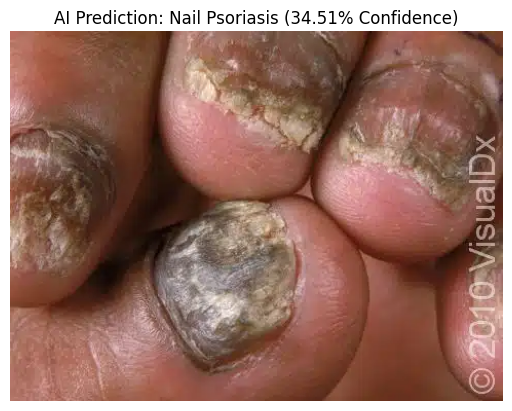


📢 CLINICAL EVALUATION: The AI is 34.51% confident this image represents a Nail Psoriasis.


In [ ]:
from google.colab import files
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2

print("👉 Click 'Choose Files' below to upload a test nail photo!")
uploaded_test = files.upload()

# 1. Match the exact validation transformation used during training
infer_transform = A.Compose([
    A.Resize(height=224, width=224),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

for filename in uploaded_test.keys():
    # Load the image
    img = cv2.imread(filename)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Apply the exact normalization tensor matrix
    augmented = infer_transform(image=img_rgb)
    img_tensor = augmented['image'].unsqueeze(0).to(device)

    # 2. Set the model brain to evaluation mode
    model.eval()
    with torch.no_grad():
        output = model(img_tensor)
        probabilities = torch.nn.functional.softmax(output, dim=1)
        confidence, predicted_class = torch.max(probabilities, 1)

    # Map predictions back to clinical classifications
    categories = {0: "Healthy Nail", 1: "Fungal Infection", 2: "Nail Psoriasis"}
    result_text = categories[predicted_class.item()]
    confidence_percentage = confidence.item() * 100

    # 3. Render the output display window
    plt.imshow(img_rgb)
    plt.title(f"AI Prediction: {result_text} ({confidence_percentage:.2f}% Confidence)")
    plt.axis('off')
    plt.show()

    print(f"\n📢 CLINICAL EVALUATION: The AI is {confidence_percentage:.2f}% confident this image represents a {result_text}.")

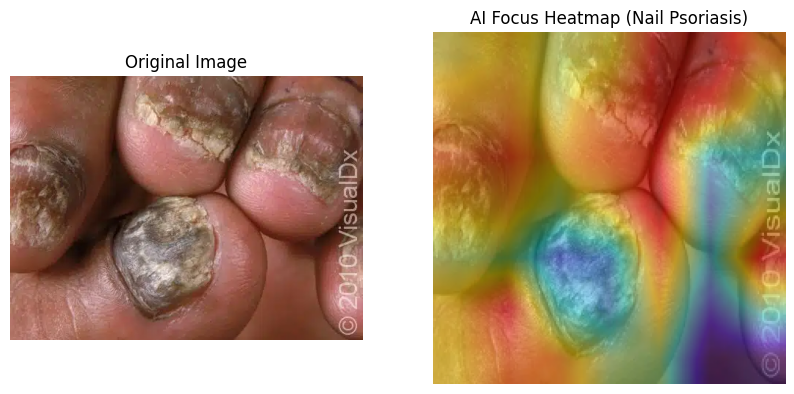

In [ ]:
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2

# 1. Choose the last convolutional layer of EfficientNet to extract the feature map
target_layer = model.network.conv_head

# Blueprint class to hook into the model's internal layers
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Register hooks to capture internal math steps
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output
    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, input_tensor, class_idx):
        self.model.zero_grad()
        output = self.model(input_tensor)
        loss = output[0, class_idx]
        loss.backward()

        # Calculate visual weight channels
        grads = self.gradients.cpu().data.numpy()[0]
        acts = self.activations.cpu().data.numpy()[0]
        weights = np.mean(grads, axis=(1, 2))

        cam = np.zeros(acts.shape[1:], dtype=np.float32)
        for i, w in enumerate(weights):
            cam += w * acts[i, :, :]

        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, (224, 224))
        cam = cam - np.min(cam)
        cam = cam / np.max(cam)
        return cam

# Initialize Grad-CAM tool
cam_extractor = GradCAM(model, target_layer)

# Generate Heatmap for your last uploaded image
# (Uses the 'img_tensor' and 'img_rgb' variables already stored in your Colab memory)
cam_mask = cam_extractor.generate(img_tensor, predicted_class.item())

# Ensure img_resized is defined correctly for overlay mapping
img_resized = cv2.resize(img_rgb, (224, 224))

# 2. Merge the heatmap with the original photo
heatmap = cv2.applyColorMap(np.uint8(255 * cam_mask), cv2.COLORMAP_JET)
heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
overlay = cv2.addWeighted(img_resized.astype(np.uint8), 0.6, heatmap, 0.4, 0)

# 3. Plot the final Explainable AI comparison side-by-side
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_rgb)
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(overlay)
axes[1].set_title(f"AI Focus Heatmap ({result_text})")
axes[1].axis('off')

plt.show()